# London Rail Network - Satellite Overlay
## Transport Network on Satellite Imagery

This notebook overlays the complete London rail network on satellite imagery, with:
- All lines shown in their official TfL colors
- Stations shown as white dots
- Landmark stations identified with unique shapes

In [33]:
# Install contextily if not available (for satellite/map tiles)
try:
    import contextily as ctx
    print("contextily available")
except ImportError:
    print("Installing contextily...")
    import subprocess
    subprocess.check_call(['pip', 'install', 'contextily'])
    import contextily as ctx
    print("contextily installed")

contextily available


In [34]:
import pyarrow.feather as feather
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.markers as mmarkers
from pathlib import Path

# Set up paths
DATA_DIR = Path('../data/processed_data')
OUTPUT_DIR = Path('../output')
OUTPUT_DIR.mkdir(exist_ok=True)

# For coordinate transformations
from pyproj import Transformer

# Transformers
osgb_to_wgs84 = Transformer.from_crs('EPSG:27700', 'EPSG:4326', always_xy=True)
osgb_to_webmerc = Transformer.from_crs('EPSG:27700', 'EPSG:3857', always_xy=True)
wgs84_to_webmerc = Transformer.from_crs('EPSG:4326', 'EPSG:3857', always_xy=True)

In [35]:
# === LINE DEFINITIONS ===

# All lines with colors
ALL_LINES = {
    # Underground
    'BAK': ('#B36305', 'Bakerloo'),
    'CEN': ('#E32017', 'Central'),
    'CIR': ('#FFD300', 'Circle'),
    'DIS': ('#00782A', 'District'),
    'HAM': ('#F3A9BB', 'Hammersmith & City'),
    'JUB': ('#A0A5A9', 'Jubilee'),
    'MET': ('#9B0056', 'Metropolitan'),
    'NTN': ('#000000', 'Northern'),
    'PIC': ('#003688', 'Piccadilly'),
    'VIC': ('#0098D4', 'Victoria'),
    'WAC': ('#95CDBA', 'Waterloo & City'),
    # Elizabeth Line
    'ELZ': ('#6950A1', 'Elizabeth'),
    # DLR
    'DLR': ('#00A4A7', 'DLR'),
    # Trams
    'TRM': ('#84B817', 'Trams'),
    # Overground
    'LIB': ('#6B717A', 'Liberty'),
    'LIO': ('#FFA600', 'Lioness'),
    'MIL': ('#00A0E2', 'Mildmay'),
    'SUF': ('#00853E', 'Suffragette'),
    'WEA': ('#9B0058', 'Weaver'),
    'WIN': ('#E21836', 'Windrush'),
}

# Landmark stations with unique markers
# Format: 'station_name_pattern': (marker, size, color, display_name)
LANDMARK_STATIONS = {
    'King\'s Cross': ('P', 200, '#E32017', "King's Cross"),  # Plus/Cross
    'Kings Cross': ('P', 200, '#E32017', "King's Cross"),
    'Waterloo': ('*', 250, '#003688', 'Waterloo'),  # Star
    'Bank': ('s', 180, '#000000', 'Bank'),  # Square
    'Liverpool Street': ('D', 180, '#9B0058', 'Liverpool Street'),  # Diamond
    'Paddington': ('p', 200, '#B36305', 'Paddington'),  # Pentagon
    'Victoria': ('^', 200, '#0098D4', 'Victoria'),  # Triangle up
    'London Bridge': ('H', 180, '#FFD300', 'London Bridge'),  # Hexagon
    'Euston': ('8', 180, '#000000', 'Euston'),  # Octagon
    'St Pancras': ('P', 180, '#E32017', 'St Pancras'),  # Plus
    'Stratford': ('h', 200, '#6950A1', 'Stratford'),  # Hexagon2
    'Canary Wharf': ('d', 180, '#A0A5A9', 'Canary Wharf'),  # Thin diamond
    'Westminster': ('o', 180, '#A0A5A9', 'Westminster'),  # Circle
    'Oxford Circus': ('X', 180, '#E32017', 'Oxford Circus'),  # X
    'Piccadilly Circus': ('o', 150, '#003688', 'Piccadilly Circus'),
    'Leicester Square': ('s', 150, '#000000', 'Leicester Square'),
    'Tower Hill': ('^', 150, '#FFD300', 'Tower Hill'),
    'Tower Gateway': ('^', 150, '#00A4A7', 'Tower Gateway'),
    'Greenwich': ('*', 150, '#00A4A7', 'Greenwich'),
    'Brixton': ('v', 150, '#0098D4', 'Brixton'),  # Triangle down
    'Heathrow': ('>', 200, '#003688', 'Heathrow'),  # Triangle right (pointing to airport)
}

## Load Data

In [36]:
# Load stop points
stops = feather.read_feather(DATA_DIR / 'ALL-StopPoints.feather')
print(f"Loaded {len(stops)} stations")

# Convert coordinates to multiple systems
stops['Easting'] = pd.to_numeric(stops['Place_Location_Easting'])
stops['Northing'] = pd.to_numeric(stops['Place_Location_Northing'])

# Convert OSGB to WGS84 (lat/lon)
lon, lat = osgb_to_wgs84.transform(stops['Easting'].values, stops['Northing'].values)
stops['Longitude'] = lon
stops['Latitude'] = lat

# Convert OSGB to Web Mercator (for map tiles)
x_merc, y_merc = osgb_to_webmerc.transform(stops['Easting'].values, stops['Northing'].values)
stops['X_WebMerc'] = x_merc
stops['Y_WebMerc'] = y_merc

# Create coordinate lookup
stop_coords = stops.set_index('AtcoCode')[[
    'Easting', 'Northing', 'Latitude', 'Longitude', 
    'X_WebMerc', 'Y_WebMerc', 'Descriptor_CommonName'
]].to_dict('index')

print(f"Coordinate range: {stops['Longitude'].min():.2f} to {stops['Longitude'].max():.2f} lon")
print(f"                  {stops['Latitude'].min():.2f} to {stops['Latitude'].max():.2f} lat")

Loaded 802 stations
Coordinate range: -0.97 to 0.33 lon
                  51.34 to 51.71 lat


In [37]:
def load_route_links(line_code):
    """Load route links for a specific line."""
    path = DATA_DIR / f'{line_code}-RouteLinks.feather'
    if path.exists():
        return feather.read_feather(path)
    return None

def get_unique_edges(route_links):
    """Extract unique edges."""
    return route_links[['From_StopPointRef', 'To_StopPointRef']].drop_duplicates()

# Load all lines
all_edges = {}
for line_code in ALL_LINES.keys():
    links = load_route_links(line_code)
    if links is not None:
        edges = get_unique_edges(links)
        all_edges[line_code] = edges
        color, name = ALL_LINES[line_code]
        print(f"{name:20s}: {len(edges):4d} edges")

print(f"\nTotal lines loaded: {len(all_edges)}")

Bakerloo            :   48 edges
Central             :   98 edges
Circle              :  120 edges
District            :  122 edges
Hammersmith & City  :   74 edges
Jubilee             :   53 edges
Metropolitan        :   74 edges
Northern            :  106 edges
Piccadilly          :  115 edges
Victoria            :   30 edges
Waterloo & City     :    2 edges
Elizabeth           :   84 edges
DLR                 :   97 edges
Trams               :   71 edges
Liberty             :    4 edges
Lioness             :   36 edges
Mildmay             :   54 edges
Suffragette         :   24 edges
Weaver              :   48 edges
Windrush            :   58 edges

Total lines loaded: 20


In [38]:
def plot_line_webmerc(ax, edges, stop_coords, color, linewidth=2, alpha=0.8):
    """Plot a line using Web Mercator coordinates."""
    for _, edge in edges.iterrows():
        from_stop = edge['From_StopPointRef']
        to_stop = edge['To_StopPointRef']
        
        if from_stop in stop_coords and to_stop in stop_coords:
            x = [stop_coords[from_stop]['X_WebMerc'], stop_coords[to_stop]['X_WebMerc']]
            y = [stop_coords[from_stop]['Y_WebMerc'], stop_coords[to_stop]['Y_WebMerc']]
            ax.plot(x, y, color=color, linewidth=linewidth, alpha=alpha, solid_capstyle='round')

def get_network_stations(edges_dict, stop_coords):
    """Get all stations with valid coordinates."""
    stations = set()
    for edges in edges_dict.values():
        stations.update(edges['From_StopPointRef'].tolist())
        stations.update(edges['To_StopPointRef'].tolist())
    return [s for s in stations if s in stop_coords]

def find_landmark_station(station_id, stop_coords):
    """Check if a station is a landmark and return its marker info."""
    if station_id not in stop_coords:
        return None
    
    name = stop_coords[station_id].get('Descriptor_CommonName', '')
    if not name:
        return None
    
    for pattern, marker_info in LANDMARK_STATIONS.items():
        if pattern.lower() in name.lower():
            return marker_info
    
    return None

## Network on Satellite Imagery

Using contextily to fetch satellite map tiles.

In [39]:
# Available tile providers for satellite imagery
print("Available satellite/aerial tile providers:")
print("- ctx.providers.Esri.WorldImagery (satellite)")
print("- ctx.providers.CartoDB.Positron (light basemap)")
print("- ctx.providers.CartoDB.DarkMatter (dark basemap)")
print("- ctx.providers.OpenStreetMap.Mapnik (street map)")
print("- ctx.providers.Stadia.StamenTonerLite (minimal)")

Available satellite/aerial tile providers:
- ctx.providers.Esri.WorldImagery (satellite)
- ctx.providers.CartoDB.Positron (light basemap)
- ctx.providers.CartoDB.DarkMatter (dark basemap)
- ctx.providers.OpenStreetMap.Mapnik (street map)
- ctx.providers.Stadia.StamenTonerLite (minimal)


In [40]:
def create_satellite_overlay(tile_provider, title_suffix, filename_suffix, base_width=20):
    """Create network overlay on satellite/map tiles with proper aspect ratio."""
    
    # Get network stations for bounds
    network_stations = get_network_stations(all_edges, stop_coords)
    
    # Calculate bounds in Web Mercator
    all_x = [stop_coords[s]['X_WebMerc'] for s in network_stations]
    all_y = [stop_coords[s]['Y_WebMerc'] for s in network_stations]
    
    margin = 5000  # meters in Web Mercator
    x_min, x_max = min(all_x) - margin, max(all_x) + margin
    y_min, y_max = min(all_y) - margin, max(all_y) + margin
    
    # Calculate proper aspect ratio
    x_range = x_max - x_min
    y_range = y_max - y_min
    aspect_ratio = y_range / x_range
    
    # Set figure size based on data aspect ratio
    fig_width = base_width
    fig_height = base_width * aspect_ratio
    
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_aspect('equal')  # Ensure equal scaling
    
    # Draw all lines
    for line_code, edges in all_edges.items():
        color, name = ALL_LINES[line_code]
        plot_line_webmerc(ax, edges, stop_coords, color, linewidth=2.5, alpha=0.9)
    
    # Collect landmark and regular stations
    landmark_points = {}  # marker_info -> list of (x, y, name)
    regular_stations = []
    
    for station in network_stations:
        x = stop_coords[station]['X_WebMerc']
        y = stop_coords[station]['Y_WebMerc']
        name = stop_coords[station].get('Descriptor_CommonName', '')
        
        marker_info = find_landmark_station(station, stop_coords)
        if marker_info:
            key = marker_info[3]  # display_name
            if key not in landmark_points:
                landmark_points[key] = (marker_info, x, y)
        else:
            regular_stations.append((x, y))
    
    # Draw regular stations as white dots
    if regular_stations:
        rx, ry = zip(*regular_stations)
        ax.scatter(rx, ry, c='white', s=15, edgecolors='black', linewidth=0.4, zorder=10, alpha=0.9)
    
    # Draw landmark stations with unique markers
    for display_name, (marker_info, x, y) in landmark_points.items():
        marker, size, color, _ = marker_info
        ax.scatter(x, y, marker=marker, s=size, c=color, edgecolors='white', 
                   linewidth=2, zorder=15, alpha=1.0)
    
    # Add basemap tiles
    try:
        ctx.add_basemap(ax, source=tile_provider, zoom='auto', alpha=0.8)
        print(f"Added basemap: {title_suffix}")
    except Exception as e:
        print(f"Could not add basemap: {e}")
        ax.set_facecolor('#E8E8E8')
    
    # Remove axis labels (coordinates not meaningful to user)
    ax.set_xticks([])
    ax.set_yticks([])
    
    
    # Create legend
    # Line legend
    line_legend = [Line2D([0], [0], color=ALL_LINES[code][0], linewidth=3, label=ALL_LINES[code][1])
                   for code in all_edges.keys()]
    
    # Landmark legend
    landmark_legend = []
    for display_name, (marker_info, x, y) in sorted(landmark_points.items()):
        marker, size, color, _ = marker_info
        landmark_legend.append(Line2D([0], [0], marker=marker, color='w', markerfacecolor=color,
                                       markeredgecolor='white', markersize=10, label=display_name, linestyle=''))
    
    # Add legends
    legend1 = ax.legend(handles=line_legend, loc='upper left', fontsize=7, 
                        ncol=2, framealpha=0.95, title='Lines')
    ax.add_artist(legend1)
    
    if landmark_legend:
        legend2 = ax.legend(handles=landmark_legend, loc='lower left', fontsize=7,
                            ncol=2, framealpha=0.95, title='Landmark Stations')
    
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'satellite_overlay_{filename_suffix}.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    return fig, ax

### Satellite Imagery (Esri World Imagery)

Added basemap: Satellite Imagery


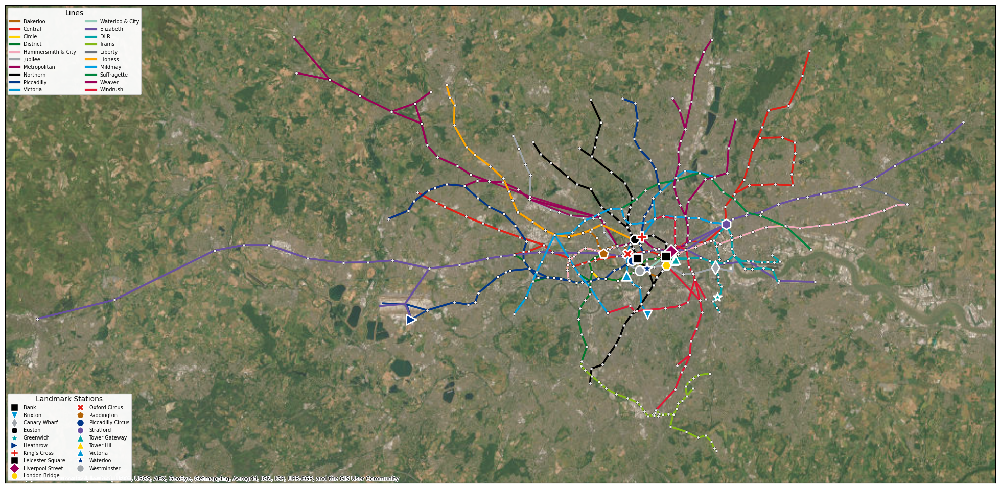

In [41]:
fig, ax = create_satellite_overlay(
    ctx.providers.Esri.WorldImagery,
    'Satellite Imagery',
    'satellite'
)

### Light Basemap (CartoDB Positron)

Added basemap: Light Basemap


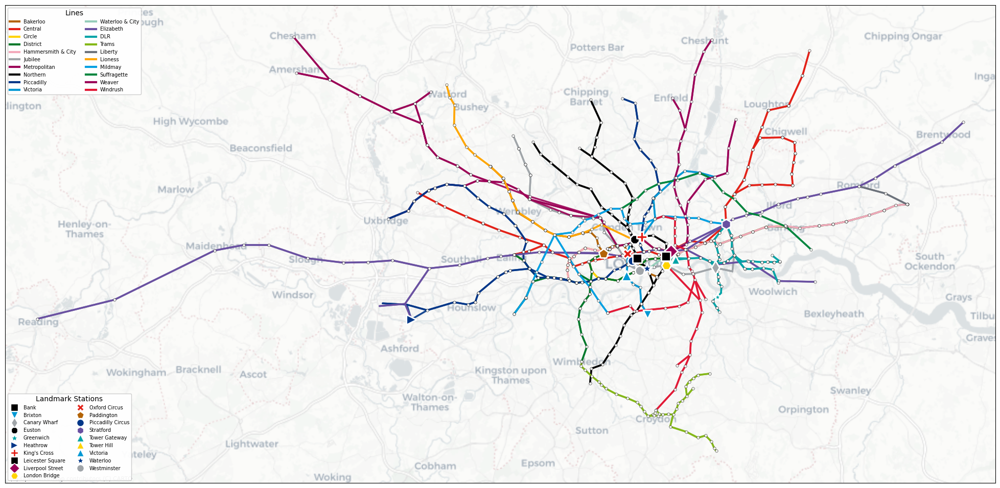

In [42]:
fig, ax = create_satellite_overlay(
    ctx.providers.CartoDB.Positron,
    'Light Basemap',
    'light'
)

### Dark Basemap (CartoDB Dark Matter)

Added basemap: Dark Basemap


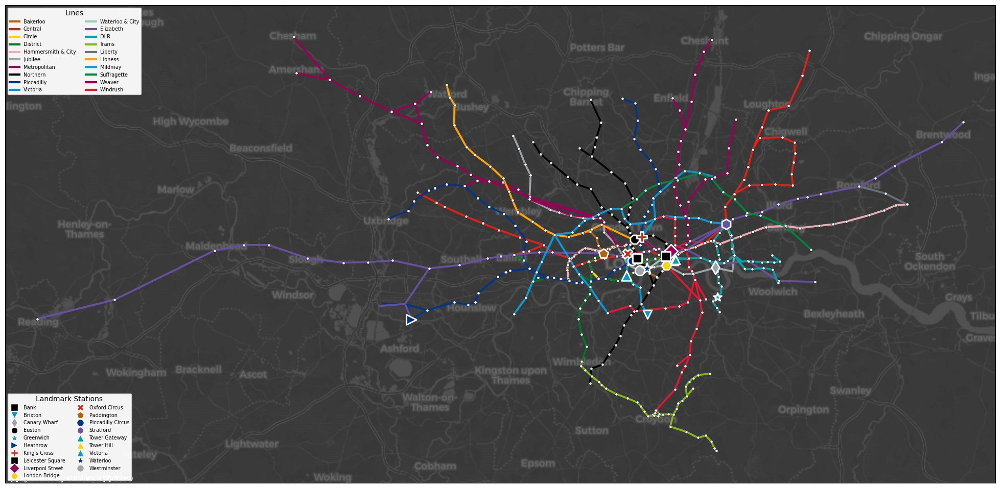

In [43]:
fig, ax = create_satellite_overlay(
    ctx.providers.CartoDB.DarkMatter,
    'Dark Basemap',
    'dark'
)

### Street Map (OpenStreetMap)

Added basemap: Street Map


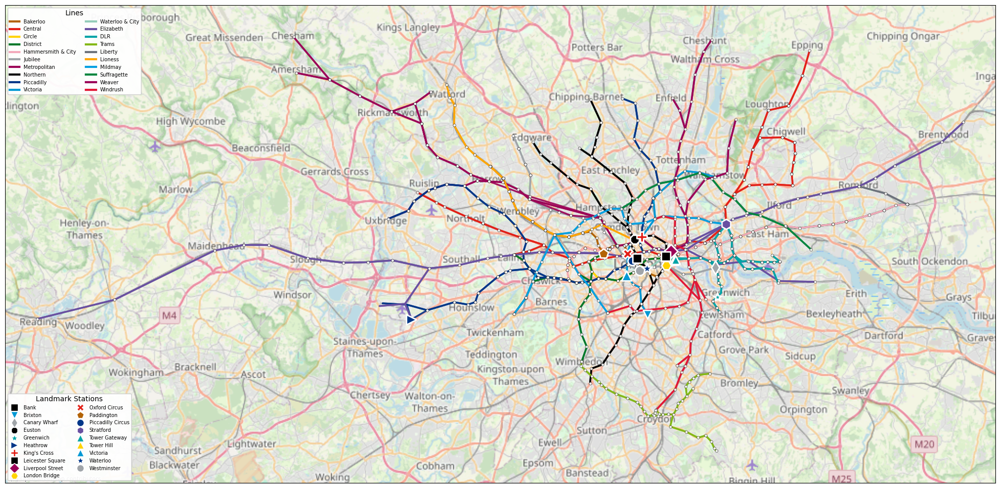

In [44]:
fig, ax = create_satellite_overlay(
    ctx.providers.OpenStreetMap.Mapnik,
    'Street Map',
    'streets'
)

## High-Resolution Satellite View (Central London Focus)

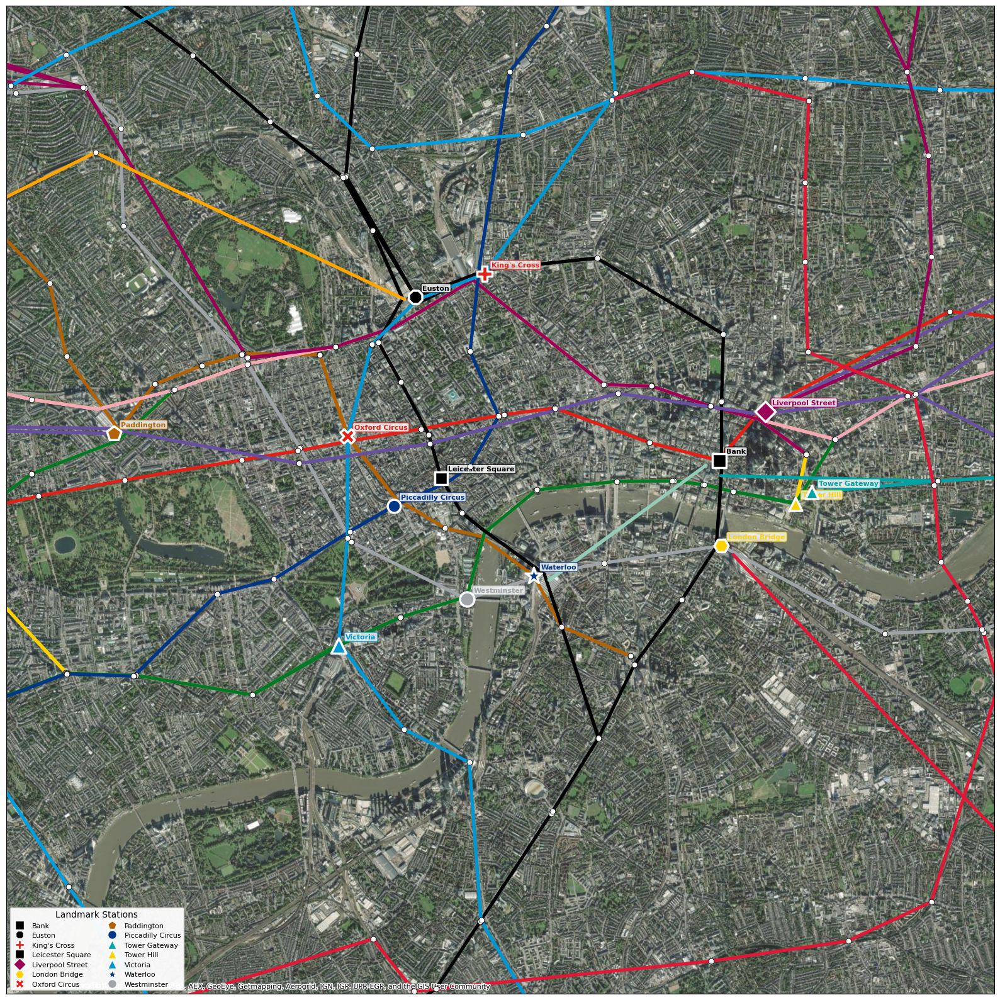

In [45]:
def create_central_london_view():
    """Create a zoomed view of central London with proper aspect ratio."""
    
    # Central London bounds (approximately zones 1-2)
    # Centered around Westminster/City
    center_lon, center_lat = -0.12, 51.51
    center_x, center_y = wgs84_to_webmerc.transform(center_lon, center_lat)
    
    # ~8km view
    radius = 8000
    x_min, x_max = center_x - radius, center_x + radius
    y_min, y_max = center_y - radius, center_y + radius
    
    # Square view for central London (equal x and y range)
    base_size = 16
    fig, ax = plt.subplots(figsize=(base_size, base_size))
    
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_aspect('equal')
    
    # Get stations in view
    network_stations = get_network_stations(all_edges, stop_coords)
    
    # Draw all lines
    for line_code, edges in all_edges.items():
        color, name = ALL_LINES[line_code]
        plot_line_webmerc(ax, edges, stop_coords, color, linewidth=3.5, alpha=0.95)
    
    # Collect stations
    landmark_points = {}
    regular_stations = []
    
    for station in network_stations:
        x = stop_coords[station]['X_WebMerc']
        y = stop_coords[station]['Y_WebMerc']
        
        # Only include stations in view
        if x_min <= x <= x_max and y_min <= y <= y_max:
            marker_info = find_landmark_station(station, stop_coords)
            if marker_info:
                key = marker_info[3]
                if key not in landmark_points:
                    landmark_points[key] = (marker_info, x, y)
            else:
                regular_stations.append((x, y))
    
    # Draw regular stations
    if regular_stations:
        rx, ry = zip(*regular_stations)
        ax.scatter(rx, ry, c='white', s=40, edgecolors='black', linewidth=0.6, zorder=10, alpha=0.95)
    
    # Draw landmarks
    for display_name, (marker_info, x, y) in landmark_points.items():
        marker, size, color, _ = marker_info
        ax.scatter(x, y, marker=marker, s=size*1.5, c=color, edgecolors='white', 
                   linewidth=2.5, zorder=15)
        # Add label
        ax.annotate(display_name, (x, y), xytext=(8, 8), textcoords='offset points',
                    fontsize=8, fontweight='bold', color=color,
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor=color))
    
    # Add satellite basemap
    try:
        ctx.add_basemap(ax, source=ctx.providers.Esri.WorldImagery, zoom=14, alpha=0.85)
    except Exception as e:
        print(f"Basemap error: {e}")
        ax.set_facecolor('#1a1a2e')
    
    ax.set_xticks([])
    ax.set_yticks([])
    
    # Compact legend
    landmark_legend = [Line2D([0], [0], marker=info[0], color='w', markerfacecolor=info[2],
                               markeredgecolor='white', markersize=10, label=name, linestyle='')
                       for name, (info, x, y) in sorted(landmark_points.items())]
    
    if landmark_legend:
        ax.legend(handles=landmark_legend, loc='lower left', fontsize=8,
                  ncol=2, framealpha=0.95, title='Landmark Stations')
    
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'satellite_central_london.png', dpi=200, bbox_inches='tight')
    plt.show()

create_central_london_view()

## Landmark Station Reference

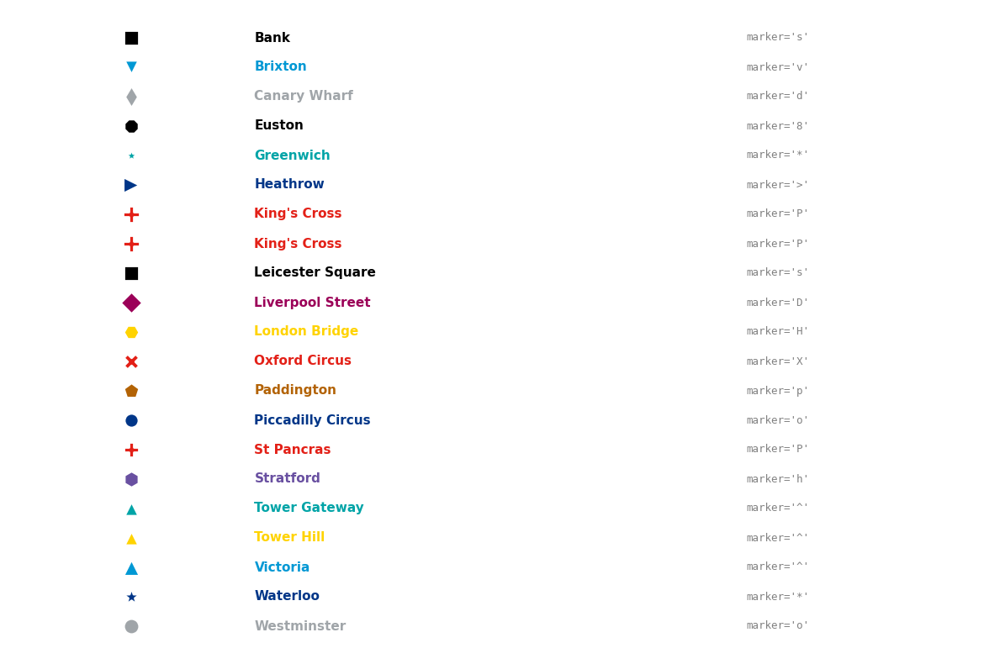

In [46]:
# Show all landmark stations and their markers
fig, ax = plt.subplots(figsize=(12, 8))
ax.set_xlim(0, 4)
ax.set_ylim(0, len(LANDMARK_STATIONS) + 1)

sorted_landmarks = sorted(LANDMARK_STATIONS.items(), key=lambda x: x[1][3])

for i, (pattern, (marker, size, color, display_name)) in enumerate(sorted_landmarks):
    y = len(sorted_landmarks) - i
    
    # Draw marker
    ax.scatter(0.5, y, marker=marker, s=size, c=color, edgecolors='white', linewidth=2)
    
    # Draw label
    ax.text(1.0, y, display_name, va='center', fontsize=11, fontweight='bold', color=color)
    
    # Draw marker name
    ax.text(3.0, y, f"marker='{marker}'", va='center', fontsize=9, family='monospace', color='gray')

ax.axis('off')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'landmark_markers_reference.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

## Network Statistics

In [47]:
# Count landmarks found in network
network_stations = get_network_stations(all_edges, stop_coords)
found_landmarks = {}

for station in network_stations:
    marker_info = find_landmark_station(station, stop_coords)
    if marker_info:
        name = marker_info[3]
        if name not in found_landmarks:
            found_landmarks[name] = stop_coords[station].get('Descriptor_CommonName', '')

print("=" * 60)
print("SATELLITE OVERLAY STATISTICS")
print("=" * 60)
print(f"\nTotal stations: {len(network_stations)}")
print(f"Landmark stations identified: {len(found_landmarks)}")
print(f"Regular stations: {len(network_stations) - len(found_landmarks)}")
print(f"\nLandmark stations found:")
for name, full_name in sorted(found_landmarks.items()):
    print(f"  - {name}: {full_name}")
print("=" * 60)

SATELLITE OVERLAY STATISTICS

Total stations: 802
Landmark stations identified: 19
Regular stations: 783

Landmark stations found:
  - Bank: Bank
  - Brixton: Brixton
  - Canary Wharf: Canary Wharf
  - Euston: Euston Station
  - Greenwich: Greenwich Station
  - Heathrow: Heathrow Terminal 4
  - King's Cross: King's Cross St. Pancras
  - Leicester Square: Leicester Square
  - Liverpool Street: London Liverpool Street
  - London Bridge: London Bridge Station
  - Oxford Circus: Oxford Circus
  - Paddington: London Paddington
  - Piccadilly Circus: Piccadilly Circus
  - Stratford: Stratford Station
  - Tower Gateway: Tower Gateway
  - Tower Hill: Tower Hill
  - Victoria: Victoria
  - Waterloo: Waterloo
  - Westminster: Westminster
